### Chat bot

In [129]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END

## Reducers

from typing import Annotated
from langgraph.graph.message import add_messages

In [130]:
class ChatBotState(TypedDict):
    chatbot_messages:Annotated[list, add_messages]


In [131]:
import os
from dotenv import load_dotenv
load_dotenv()

#os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")


In [132]:
from langchain_groq import ChatGroq

llm_groq = ChatGroq(
    model="qwen/qwen3.8-27b",
    api_key=os.getenv("GROQ_API_KEY")
)

# response = llm_groq.invoke(
#     "Hey I am Krish and I like to play cricket"
# )

# print(response.content)

### We Will start With Creating Nodes

In [133]:
# def chatbot(state:ChatBotState):
#     return {"chatbot_messages":[llm_groq.invoke(state['chatbot_messages'])]}

from langchain_core.messages import AIMessage, HumanMessage

def chatbot(state: ChatBotState):
    response_content = ""

    for chunk in llm_groq.stream(state["chatbot_messages"]):
        if chunk.content:
            print(chunk.content, end="", flush=True)
            response_content += chunk.content

    return {
        "chatbot_messages": [
            AIMessage(content=response_content)
        ]
    }

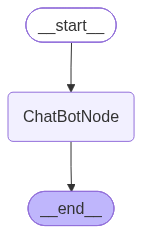

In [134]:
graph=StateGraph(ChatBotState)

graph.add_node("ChatBotNode",chatbot)


graph.add_edge(START,"ChatBotNode")
graph.add_edge("ChatBotNode",END)


graph_builder=graph.compile()


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [135]:
## Invocation

#graph_builder.invoke({'chatbot_messages':"Hi,My name is NN And I like cricket"})

In [136]:
# for event in graph_builder.stream({"chatbot_messages":"Hi,My name is NN And I like cricket"}):
#     print(event)


# Below is for stream token by token
graph_builder.invoke({
    "chatbot_messages": [
        HumanMessage(content="wrtite 500 words easy")
    ]
})

The morning sun peeked through the thin curtains, casting long, golden stripes across the wooden floor. Leo stretched his arms high above his head, feeling a satisfying pop in his shoulders. It was Saturday, which meant no alarm clock, no rush to the office, and no emails waiting to pile up in his inbox. For the first time in weeks, he felt a strange sense of calm. He grinned, knowing that today was going to be different. Today was for the garden.

He shuffled into the kitchen, his bare feet slapping softly against the cool tile. The house was quiet, save for the gentle hum of the refrigerator and the distant chirping of birds outside. He filled a mug with hot water and dropped in a bag of chamomile tea. The sweet, floral scent rose into the air, wrapping around him like a warm blanket. He took a slow sip, letting the heat settle in his chest. It was a small ritual, but it always helped him slow down.

After finishing his tea, Leo grabbed his gardening gloves from the hook by the back 

{'chatbot_messages': [HumanMessage(content='wrtite 500 words easy', additional_kwargs={}, response_metadata={}, id='0da1ba25-f153-463a-be74-7523b542f398'),
  AIMessage(content='The morning sun peeked through the thin curtains, casting long, golden stripes across the wooden floor. Leo stretched his arms high above his head, feeling a satisfying pop in his shoulders. It was Saturday, which meant no alarm clock, no rush to the office, and no emails waiting to pile up in his inbox. For the first time in weeks, he felt a strange sense of calm. He grinned, knowing that today was going to be different. Today was for the garden.\n\nHe shuffled into the kitchen, his bare feet slapping softly against the cool tile. The house was quiet, save for the gentle hum of the refrigerator and the distant chirping of birds outside. He filled a mug with hot water and dropped in a bag of chamomile tea. The sweet, floral scent rose into the air, wrapping around him like a warm blanket. He took a slow sip, let